## Initiating EDA

In [53]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import warnings
warnings.filterwarnings('ignore')

In [54]:
df = pd.read_csv('../data/raw/WeightedSentimentTelemedicineDataset.csv', low_memory=False)

## A. Data Description

FROM README.txt

List of Attribute 
    This dataset is designed to support the development of automated classification models for user reviews in telemedicine applications. It also includes additional attributes, such as weight. The list of attributes is shown in the table below. 

Attribute Description 
- platform : Application distributor platform 
- app_name : Application name 
- rating : Application user satisfaction score  
- review : Application user review 
- sentiment : Data label (negative, neutral, positive) 
- weight : User review complexity label (uninformative, informative, complex) 

Value of the Data 
- The Weighted Telemedicine Sentiment Dataset contains 19,680 manually annotated Indonesian-language user reviews from three telemedicine applications, labeled with three sentiment classes (Positive, Neutral, Negative) and a weight attribute (Uninformative, Informative, Complex) indicating review informativeness. 
- The annotation was performed by two annotators following a documented guideline reviewed by a psychology expert, with inter-annotator agreement measured using Cohen's Kappa, which indicated substantial agreement (κ = 0.752), thereby enabling other researchers to assess label reliability. 
- Facilitates and supports experiments in advanced NLP technologies, including BERT, LSTM, and LLMs, such as the user review sentiment classification task. 
- This dataset introduces a weight attribute (Uninformative, Informative, Complex), which adds a crucial secondary dimension. This enables researchers to analyze not only what the user feels but also the substantive value of the review, thereby facilitating more advanced tasks such as Aspect-Based Sentiment Analysis (ABSA). On the other hand, this label can be enabled to curate the data, such as filtering uninformative reviews or studying the characteristics of complex user feedback, while telemedicine providers can use the labeled reviews to examine user-reported service issues. 

Data Annotation 
- The dataset was manually annotated by two annotators 

- A fundamental difference from the previous dataset lies in the manual annotation process, which was validated by Psychology experts, ensuring that the resulting annotations align with scientific psychological principles 


In [55]:
df.head(5)

,platform,app_name,rating,review,sentiment,weight
0,Play Store,Alodokter —Chat Bersama Dokter,5,oke,NEUTRAL,UNINFORMATIVE
1,Play Store,Alodokter —Chat Bersama Dokter,2,"baru download, mau daftar ga bisa2. haduuhhh terus buat apa di download doang klo daftar aja ga bisa.",NEGATIVE,UNINFORMATIVE
2,Play Store,Alodokter —Chat Bersama Dokter,1,mending chat sama chatgpt dari pada alodokter. ga bisa keluarin surat dokter gara2 abis katanya. jawaban nya jg textbook banget. mending chat AI aja gratis.,NEGATIVE,UNINFORMATIVE
3,Play Store,Alodokter —Chat Bersama Dokter,5,Sangat Memuaskan,POSITIVE,UNINFORMATIVE
4,Play Store,Alodokter —Chat Bersama Dokter,5,"saya usia 54 thn sering sakit gigi, klau sakit saya minum obat Oskadon sembuh lama kemudian sekarang kambuh lagi dokter terus saya minum obat Oskadon lagi sembuh sebentar tapi sakit lagi yang ingin saya tanyakan obat apa yang tidak kambuh lagi dokter pada hal saya sudah menjaga kebersihan",NEUTRAL,UNINFORMATIVE


In [56]:
df['platform'].value_counts()

platform
Play Store    19680
Name: count, dtype: int64

In [57]:
df['app_name'].value_counts()

app_name
Alodokter —Chat Bersama Dokter    7602
Halodoc: Dokter, Obat & Lab       7295
KlikDokter: Jaga Sehatmu          4783
Name: count, dtype: int64

In [58]:
df['weight'].value_counts()

weight
UNINFORMATIVE    16572
INFORMATIVE       2718
COMPLEX            390
Name: count, dtype: int64

### A.1 Null value & Duplicate detection

In [59]:
df['review_character_length'] = df['review'].str.len()
df['review_word_count'] = df['review'].str.split().str.len()

In [60]:
# 5. Duplikat
print(df['review'].str.lower().str.strip().duplicated().sum())

1305


### A.2 'weight' column overview

In [61]:
df[df['weight'] == 'UNINFORMATIVE']

,platform,app_name,rating,review,sentiment,weight,review_character_length,review_word_count
0,Play Store,Alodokter —Chat Bersama Dokter,5,oke,NEUTRAL,UNINFORMATIVE,3.0,1.0
1,Play Store,Alodokter —Chat Bersama Dokter,2,"baru download, mau daftar ga bisa2. haduuhhh terus buat apa di download doang klo daftar aja ga bisa.",NEGATIVE,UNINFORMATIVE,101.0,18.0
2,Play Store,Alodokter —Chat Bersama Dokter,1,mending chat sama chatgpt dari pada alodokter. ga bisa keluarin surat dokter gara2 abis katanya. jawaban nya jg textbook banget. mending chat AI aja gratis.,NEGATIVE,UNINFORMATIVE,156.0,25.0
3,Play Store,Alodokter —Chat Bersama Dokter,5,Sangat Memuaskan,POSITIVE,UNINFORMATIVE,16.0,2.0
4,Play Store,Alodokter —Chat Bersama Dokter,5,"saya usia 54 thn sering sakit gigi, klau sakit saya minum obat Oskadon sembuh lama kemudian sekarang kambuh lagi dokter terus saya minum obat Oskadon lagi sembuh sebentar tapi sakit lagi yang ingin saya tanyakan obat apa yang tidak kambuh lagi dokter pada hal saya sudah menjaga kebersihan",NEUTRAL,UNINFORMATIVE,289.0,48.0
...,...,...,...,...,...,...,...,...
19675,Play Store,KlikDokter: Jaga Sehatmu,5,Mempermudah mngetahui tntng kshatan gaya hdup yg benar,POSITIVE,UNINFORMATIVE,54.0,8.0
19676,Play Store,KlikDokter: Jaga Sehatmu,5,Semua ulasan,POSITIVE,UNINFORMATIVE,12.0,2.0
19677,Play Store,KlikDokter: Jaga Sehatmu,4,BAguz,POSITIVE,UNINFORMATIVE,5.0,1.0
19678,Play Store,KlikDokter: Jaga Sehatmu,5,Mempermudah kita jika mau berkonsultasi dengan dokter. Keren :),POSITIVE,UNINFORMATIVE,63.0,9.0


In [62]:
df[df['weight'] == 'INFORMATIVE'].head(5)

,platform,app_name,rating,review,sentiment,weight,review_character_length,review_word_count
9,Play Store,Alodokter —Chat Bersama Dokter,5,"aplikasi ini engga amanah saya order yang instan tapi di kirim esok hari. aneh, seharusnya kalau gabisa kirim hari ini ga usah ada pengiriman instan",NEGATIVE,INFORMATIVE,148.0,25.0
11,Play Store,Alodokter —Chat Bersama Dokter,1,"syaa sudah konsul dokter SP.M di kasih resep obat, tp ketika saya mau beli d alloshop ga bisa di gunakan resep dokternya, saya di paksa membeli obat di toko yg mereka rekomendasikan sementra saya tidak bisa memilih toko yg saya pilih dengan resep dokter yang saya punya, kalau ga ada bintang saya kasih nol bintang .. benar2 mengecewakan",NEGATIVE,INFORMATIVE,337.0,58.0
16,Play Store,Alodokter —Chat Bersama Dokter,5,kapok berobat d Alo dokter obat sudah d beli GK d kirim obat buat kesembuhan ngirim nya sembrono,NEGATIVE,INFORMATIVE,98.0,18.0
29,Play Store,Alodokter —Chat Bersama Dokter,5,"GK bisa daftar, bahaya ini. mohon dicoba kembali waktu daftar,kayak ngambil data ajaaa.",NEGATIVE,INFORMATIVE,88.0,13.0
39,Play Store,Alodokter —Chat Bersama Dokter,5,"mau tanya, ini konsul doang atau konsul terus dapat resepnya? info dong yang sudah pernah konsul.. makasih",NEUTRAL,INFORMATIVE,106.0,17.0


In [63]:
df[df['weight'] == 'COMPLEX'].head(5)

,platform,app_name,rating,review,sentiment,weight,review_character_length,review_word_count
42,Play Store,Alodokter —Chat Bersama Dokter,1,"setiap chat dokter, selalu je scroll otomatis kebawah jadi antara pasien dgn dokter kesulitan baca chat keluhannya yg panjang, gmna nih? masa chat pendek pendek utk ngasih tau keluhannya. segera perbaiki ya..",NEGATIVE,COMPLEX,208.0,32.0
49,Play Store,Alodokter —Chat Bersama Dokter,4,"tolong memberikan deskripsi di aplikasi nya sehabis minum obat,jgn sehabis chat dgn dokternya,Krn reaksi obat nya berbeda-beda setiap pasien",POSITIVE,COMPLEX,140.0,19.0
82,Play Store,Alodokter —Chat Bersama Dokter,5,belum jg ngmong. udah habis masa pembayaran nya. kelamaan muter2. lain kali beri waktu agak pnjang. tau gak dokter aja baru jawab selamat malam. transaksi waktu udh habis. ngmong jg belom. gimana sih ? GK apa saya beri bintang 5.,NEGATIVE,COMPLEX,230.0,40.0
96,Play Store,Alodokter —Chat Bersama Dokter,5,"Sangat terbantu dengan resep dokternya, pengiriman K-24 juga cepat. Tapi tolong tim IT Alodokter perbaiki bug ini: Pertama, status resep masih 'Menunggu Pembayaran' padahal pesanan sudah dibayar dan dalam pengiriman. Kedua, kalau kita lagi ngetik di chat dokter terus pindah aplikasi sebentar, ketikannya langsung hilang bersih. Bikin capek ngetik ulang. Semoga update ke depannya bug ini sudah hilang ya",POSITIVE,COMPLEX,404.0,59.0
119,Play Store,Alodokter —Chat Bersama Dokter,5,tingkatkan lagi pelyananan supaya semua bisa di akses,POSITIVE,COMPLEX,53.0,8.0


In [64]:
df.groupby('weight')['review_character_length'].describe().round(3).T

weight,COMPLEX,INFORMATIVE,UNINFORMATIVE
count,390.000,2718.000,16520.000
mean,307.359,192.678,52.208
std,116.397,99.450,42.546
min,53.000,13.000,2.000
25%,218.250,123.000,22.000
50%,287.500,172.000,40.000
75%,408.750,236.000,71.000
max,529.000,595.000,499.000


In [65]:
df[(df['review_character_length'] > 71) & (df['weight'] == 'UNINFORMATIVE')]

,platform,app_name,rating,review,sentiment,weight,review_character_length,review_word_count
1,Play Store,Alodokter —Chat Bersama Dokter,2,"baru download, mau daftar ga bisa2. haduuhhh terus buat apa di download doang klo daftar aja ga bisa.",NEGATIVE,UNINFORMATIVE,101.0,18.0
2,Play Store,Alodokter —Chat Bersama Dokter,1,mending chat sama chatgpt dari pada alodokter. ga bisa keluarin surat dokter gara2 abis katanya. jawaban nya jg textbook banget. mending chat AI aja gratis.,NEGATIVE,UNINFORMATIVE,156.0,25.0
4,Play Store,Alodokter —Chat Bersama Dokter,5,"saya usia 54 thn sering sakit gigi, klau sakit saya minum obat Oskadon sembuh lama kemudian sekarang kambuh lagi dokter terus saya minum obat Oskadon lagi sembuh sebentar tapi sakit lagi yang ingin saya tanyakan obat apa yang tidak kambuh lagi dokter pada hal saya sudah menjaga kebersihan",NEUTRAL,UNINFORMATIVE,289.0,48.0
5,Play Store,Alodokter —Chat Bersama Dokter,2,dokternya responnya lama .... ( Semoga bisa diperbaiki ya dok responnya ) terimkasih semangat terus,NEGATIVE,UNINFORMATIVE,99.0,15.0
13,Play Store,Alodokter —Chat Bersama Dokter,1,sedikit kecewa. karena psikolog saya yg salah pilih tidak merespon malah digantik sama psikolog lain. padahal saya lagi cari psikolog yg nonis. terima kasih,NEGATIVE,UNINFORMATIVE,156.0,24.0
...,...,...,...,...,...,...,...,...
19640,Play Store,KlikDokter: Jaga Sehatmu,5,"sangat bermanfaat sekali buat kita dn keluarga, saya mohon lebih di perbanyak lagi untuk dokter spesialisnya",POSITIVE,UNINFORMATIVE,108.0,16.0
19648,Play Store,KlikDokter: Jaga Sehatmu,5,Sangat penting buat saya untuk mengetahui tentang kesehatan dan info obat2tan makasih klik dokter.,POSITIVE,UNINFORMATIVE,98.0,14.0
19650,Play Store,KlikDokter: Jaga Sehatmu,4,Dengan aplikasi ini saya lebih mudah untuk mendapatkan informasi tentang kesehatan,POSITIVE,UNINFORMATIVE,82.0,11.0
19657,Play Store,KlikDokter: Jaga Sehatmu,4,Trimakasih banyak klinik dokter.. saya sangat suka dgn ada nya aplikasi ini berkat adax klinik dokter sya banyak tahu tentang kesehatan.,POSITIVE,UNINFORMATIVE,136.0,21.0


In [66]:
df.groupby('weight')['rating'].describe().T

weight,COMPLEX,INFORMATIVE,UNINFORMATIVE
count,390.000000,2718.000000,16572.000000
mean,2.923077,3.278514,4.292300
std,1.698095,1.823674,1.403851
min,1.000000,1.000000,1.000000
25%,1.000000,1.000000,5.000000
50%,3.000000,4.000000,5.000000
75%,5.000000,5.000000,5.000000
max,5.000000,5.000000,5.000000


Kebanyakan kolom uninformative adalah rating positive, bahkan di Q 25% sudah didominasi di 5, sedangkan informative memiliki rating positive namun tidak sempurna, dan complex cenderung memiliki rating negative.

### A.3 'sentiment' column overview 

In [67]:
df['sentiment'].value_counts()

sentiment
POSITIVE    14748
NEGATIVE     4221
NEUTRAL       711
Name: count, dtype: int64

In [68]:
df.groupby('sentiment')['rating'].value_counts().T

sentiment  rating
NEGATIVE   1          3200
           2           457
           3           414
           4            79
           5            71
NEUTRAL    5           329
           3           187
           4            96
           2            79
           1            20
POSITIVE   5         13612
           4           990
           3            79
           2            64
           1             3
Name: count, dtype: int64

In [69]:
df.groupby('app_name')['sentiment'].value_counts().T

app_name                        sentiment
Alodokter —Chat Bersama Dokter  POSITIVE     4915
                                NEGATIVE     2260
                                NEUTRAL       427
Halodoc: Dokter, Obat & Lab     POSITIVE     6198
                                NEGATIVE     1030
                                NEUTRAL        67
KlikDokter: Jaga Sehatmu        POSITIVE     3635
                                NEGATIVE      931
                                NEUTRAL       217
Name: count, dtype: int64

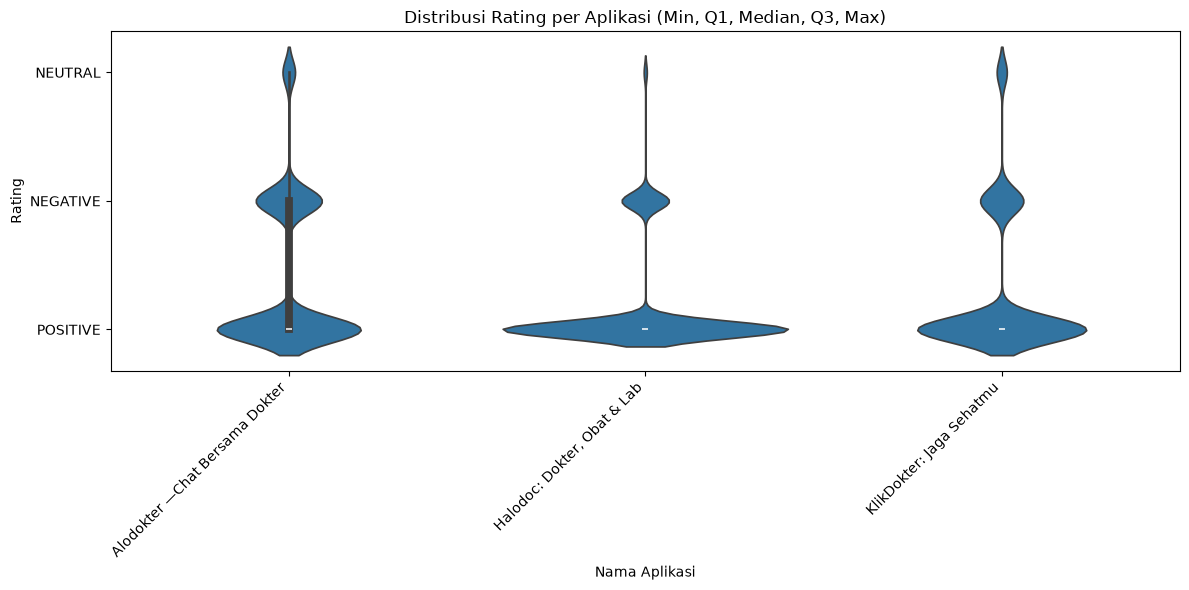

In [70]:
plt.figure(figsize=(12, 6))
sns.violinplot(data=df, x='app_name', y='sentiment')

plt.title('Distribusi Rating per Aplikasi (Min, Q1, Median, Q3, Max)')
plt.xlabel('Nama Aplikasi')
plt.ylabel('Rating')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

#### A.3.1 (!!REVIEW THIS!!) Inspecting Neutral Sentiment

In [71]:
df['sentiment'].value_counts()

sentiment
POSITIVE    14748
NEGATIVE     4221
NEUTRAL       711
Name: count, dtype: int64

In [72]:
df.groupby('app_name')['sentiment'].value_counts()

app_name                        sentiment
Alodokter —Chat Bersama Dokter  POSITIVE     4915
                                NEGATIVE     2260
                                NEUTRAL       427
Halodoc: Dokter, Obat & Lab     POSITIVE     6198
                                NEGATIVE     1030
                                NEUTRAL        67
KlikDokter: Jaga Sehatmu        POSITIVE     3635
                                NEGATIVE      931
                                NEUTRAL       217
Name: count, dtype: int64

In [73]:
df.columns

Index(['platform', 'app_name', 'rating', 'review', 'sentiment', 'weight',
       'review_character_length', 'review_word_count'],
      dtype='object')

In [74]:
temp = df[(df['app_name'] == 'Alodokter —Chat Bersama Dokter') & (df['sentiment'] == 'NEUTRAL')]
pd.set_option("display.max_colwidth", None)
display(temp[['weight', 'review', 'rating', 'sentiment']])



,weight,review,rating,sentiment
0,UNINFORMATIVE,oke,5,NEUTRAL
4,UNINFORMATIVE,"saya usia 54 thn sering sakit gigi, klau sakit saya minum obat Oskadon sembuh lama kemudian sekarang kambuh lagi dokter terus saya minum obat Oskadon lagi sembuh sebentar tapi sakit lagi yang ingin saya tanyakan obat apa yang tidak kambuh lagi dokter pada hal saya sudah menjaga kebersihan",5,NEUTRAL
8,UNINFORMATIVE,good job,5,NEUTRAL
10,UNINFORMATIVE,ok,5,NEUTRAL
12,UNINFORMATIVE,baik,4,NEUTRAL
...,...,...,...,...
9408,UNINFORMATIVE,blngapa,5,NEUTRAL
9423,UNINFORMATIVE,cari tau tentang kesehatan.,4,NEUTRAL
9427,UNINFORMATIVE,Apa salep aman anti septik buat bisul?,5,NEUTRAL
9558,INFORMATIVE,Anak saya udah 10 hari tapi badannya masih panas dan klu panas kakinya terasa dingin dan tangannya juga dingin minumin parasetamol dan amozsilin masih turun naik panasnya apa masalahnya dan apa obat yang bagus? . Apa obat yang bagus buat penderita tipes,5,NEUTRAL


In [75]:
len(df[(df['app_name'] == 'Alodokter —Chat Bersama Dokter') & (df['sentiment'] == 'NEUTRAL')])

427

Relabeling oke, goodjob, baik, dst

In [76]:
positive_keywords = [
    "oke", "ok", "okee", "okey", "good job", "goodjob", 
    "baik", 'baikk', 'baiik', "bagus", "sip", 'baik dokternya', 'ty',
    "siap", "mantap", 'good', 'terima kasih', 'nice', 'thank you', 'terimakasih',
    'trimakasih', 'sehat selalu', 'sangat berguna', 'okk', 'bagus', 'approved',
    'like', 'wow', 'terimaksih', 'makasih',
]

# 2. Buat regex pattern untuk mencocokkan kata (case-insensitive & menghapus spasi/karakter berlebih)
pattern = r"\b(" + "|".join(positive_keywords) + r")\b"

# 3. Tentukan kondisi: teks cocok dengan pattern DAN rating > 3
condition = df["review"].str.strip().str.lower().str.contains(
    pattern, regex=True, na=False
) & (df["rating"] > 3)

# 4. Ubah label sentimen menjadi POSITIVE jika memenuhi kondisi
df.loc[condition, "sentiment"] = "POSITIVE"


In [77]:
df.loc[104]

platform                                       Play Store
app_name                   Alodokter —Chat Bersama Dokter
rating                                                  5
review                                              baiik
sentiment                                        POSITIVE
weight                                      UNINFORMATIVE
review_character_length                               5.0
review_word_count                                     1.0
Name: 104, dtype: object

In [78]:
len(df[(df['app_name'] == 'Alodokter —Chat Bersama Dokter') & (df['sentiment'] == 'NEUTRAL')])

367

In [79]:
temp = df[df['sentiment'] == 'NEUTRAL']
display(temp[['weight', 'review', 'rating', 'sentiment']])

,weight,review,rating,sentiment
4,UNINFORMATIVE,"saya usia 54 thn sering sakit gigi, klau sakit saya minum obat Oskadon sembuh lama kemudian sekarang kambuh lagi dokter terus saya minum obat Oskadon lagi sembuh sebentar tapi sakit lagi yang ingin saya tanyakan obat apa yang tidak kambuh lagi dokter pada hal saya sudah menjaga kebersihan",5,NEUTRAL
14,UNINFORMATIVE,sy mau tanya apa obat yg paling aman untuk penyakit tulang ekor yg kegeser akibat dr jatuh berkalikali,2,NEUTRAL
17,UNINFORMATIVE,"sore dok,, saya umur 57 tahun mengkonsumsi multivitamin renovit gold dan vit B12 IPI serta magnesium apakah tidak over kalau mengkonsumsi nature e yang putih 200UI",5,NEUTRAL
20,UNINFORMATIVE,saya punya penyakit mag apakah bisa di sembuhkan dengan minum habbatusauda,5,NEUTRAL
25,UNINFORMATIVE,"dokter sudah satu bulan ini saya menderita gatal"" diseluruh muka hingga kepala. apa solusinya?",2,NEUTRAL
...,...,...,...,...
19620,UNINFORMATIVE,paten,5,NEUTRAL
19649,UNINFORMATIVE,Siiiiiip,5,NEUTRAL
19658,UNINFORMATIVE,mencoba tau informasi kesehatan,4,NEUTRAL
19659,UNINFORMATIVE,Lumaya,4,NEUTRAL


In [80]:
temp = df[df['review'].str.contains(r'(?=.*\bapa\b)(?=.*\?)', regex=True, na=False, case=False)]
len(temp)

125

In [81]:
pd.set_option("display.max_colwidth", 100)

### A.4 Rating score overview 
based on each App review

In [82]:
df.groupby('app_name')['rating'].describe().T

app_name,Alodokter —Chat Bersama Dokter,"Halodoc: Dokter, Obat & Lab",KlikDokter: Jaga Sehatmu
count,7602.000000,7295.000000,4783.000000
mean,3.830571,4.426456,4.133807
std,1.696626,1.297648,1.468074
min,1.000000,1.000000,1.000000
25%,2.000000,5.000000,4.000000
50%,5.000000,5.000000,5.000000
75%,5.000000,5.000000,5.000000
max,5.000000,5.000000,5.000000


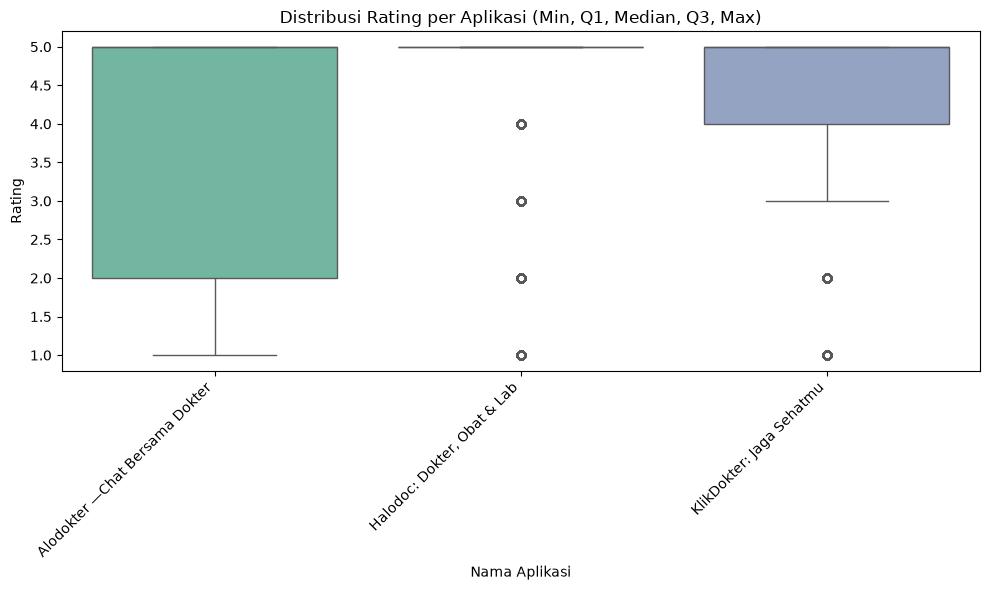

In [83]:
plt.figure(figsize=(10, 6))
sns.boxplot(data=df, x='app_name', y='rating', palette='Set2')

plt.title('Distribusi Rating per Aplikasi (Min, Q1, Median, Q3, Max)')
plt.xlabel('Nama Aplikasi')
plt.ylabel('Rating')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

### A.5 Potential Anomaly

In [84]:
df[(df['sentiment'] == 'NEGATIVE') & (df['rating'] > 3)]

,platform,app_name,rating,review,sentiment,weight,review_character_length,review_word_count
9,Play Store,Alodokter —Chat Bersama Dokter,5,"aplikasi ini engga amanah saya order yang instan tapi di kirim esok hari. aneh, seharusnya kalau...",NEGATIVE,INFORMATIVE,148.0,25.0
16,Play Store,Alodokter —Chat Bersama Dokter,5,kapok berobat d Alo dokter obat sudah d beli GK d kirim obat buat kesembuhan ngirim nya sembrono,NEGATIVE,INFORMATIVE,98.0,18.0
29,Play Store,Alodokter —Chat Bersama Dokter,5,"GK bisa daftar, bahaya ini. mohon dicoba kembali waktu daftar,kayak ngambil data ajaaa.",NEGATIVE,INFORMATIVE,88.0,13.0
40,Play Store,Alodokter —Chat Bersama Dokter,4,gak ada pembayaran lewat E-walet dana,NEGATIVE,UNINFORMATIVE,37.0,6.0
68,Play Store,Alodokter —Chat Bersama Dokter,5,"jangan mau berlangganan ,pembohong katanya unlimited tapi tetap di batasi,,maunya aplikasi ini k...",NEGATIVE,INFORMATIVE,323.0,45.0
...,...,...,...,...,...,...,...,...
17952,Play Store,KlikDokter: Jaga Sehatmu,4,Waktu konsultasi kurang lama.,NEGATIVE,INFORMATIVE,29.0,4.0
18858,Play Store,KlikDokter: Jaga Sehatmu,4,"saya sudah daftar ,tapi kode verifikasi tidak di kirim kirim.",NEGATIVE,UNINFORMATIVE,61.0,10.0
19035,Play Store,KlikDokter: Jaga Sehatmu,4,tlng jwbany lbih dipejlas,NEGATIVE,INFORMATIVE,25.0,4.0
19292,Play Store,KlikDokter: Jaga Sehatmu,5,Koyok taek,NEGATIVE,UNINFORMATIVE,10.0,2.0


### A.6 Sentiment x Weight overview

In [85]:
# 1. Sentiment x weight
print(pd.crosstab(df['sentiment'], df['weight'], margins=True))

weight     COMPLEX  INFORMATIVE  UNINFORMATIVE    All
sentiment                                            
NEGATIVE       207         1217           2777   4201
NEUTRAL         32           94            483    609
POSITIVE       151         1407          13312  14870
All            390         2718          16572  19680


In [86]:
print(pd.crosstab(df['sentiment'], df['weight'], normalize='columns').round(3))

weight     COMPLEX  INFORMATIVE  UNINFORMATIVE
sentiment                                     
NEGATIVE     0.531        0.448          0.168
NEUTRAL      0.082        0.035          0.029
POSITIVE     0.387        0.518          0.803


In [87]:
# 2. Weight per aplikasi
print(pd.crosstab(df['app_name'], df['weight'], normalize='index').round(3))

weight                          COMPLEX  INFORMATIVE  UNINFORMATIVE
app_name                                                           
Alodokter —Chat Bersama Dokter    0.022        0.137          0.842
Halodoc: Dokter, Obat & Lab       0.017        0.121          0.862
KlikDokter: Jaga Sehatmu          0.021        0.167          0.812


In [88]:
print(df.groupby('weight')['review_word_count'].describe())

                 count       mean        std  min   25%   50%   75%    max
weight                                                                    
COMPLEX          390.0  47.866667  18.721684  8.0  33.0  45.0  63.0   89.0
INFORMATIVE     2718.0  30.149375  16.189954  2.0  18.0  26.0  37.0  111.0
UNINFORMATIVE  16520.0   7.930872   6.737514  1.0   3.0   6.0  11.0   90.0


In [89]:
# 4. Weight di hard subset
hard = df[
    (df['sentiment'] == 'NEUTRAL') |
    ((df['sentiment'] == 'NEGATIVE') & (df['rating'] >= 4)) |
    ((df['sentiment'] == 'POSITIVE') & (df['rating'] <= 2))
]
print(pd.crosstab(hard['sentiment'], hard['weight']))

weight     COMPLEX  INFORMATIVE  UNINFORMATIVE
sentiment                                     
NEGATIVE        16           46             68
NEUTRAL         32           94            483
POSITIVE         4           19             44


In [90]:
print(f"Review length dist: \n{df['review_character_length'].describe()}")

Review length dist: 
count    19628.000000
mean        76.729264
std         81.154154
min          2.000000
25%         25.000000
50%         48.000000
75%         98.000000
max        595.000000
Name: review_character_length, dtype: float64


In [91]:
neg_words = {'tidak', 'tak', 'bukan', 'belum', 'jangan', 'kurang', 'tapi', 'tetapi', 'namun'}

def has_neg(text):
    return any(t in neg_words for t in str(text).lower().split())

df['has_neg'] = df['review'].map(has_neg)
print(df['has_neg'].mean())                                # proporsi review yang kehilangan negasi
print(df.groupby('sentiment')['has_neg'].mean().round(3))  # per kelas

0.1410569105691057
sentiment
NEGATIVE    0.409
NEUTRAL     0.166
POSITIVE    0.064
Name: has_neg, dtype: float64


## B. Text Cleaning & Normalizing

In [92]:
from pathlib import Path
import sys, os


ROOT_DIR = Path.cwd().resolve().parent
sys.path.insert(0, str(ROOT_DIR))

from config.config_script import RAW_DATA_DIR, DEFAULT_NORM_DICT, WEIGHTED_SPLIT_DATA_DIR 
from src.preprocessor import TextPreprocessing

### B.1 Cleaning & Normalizing

In [93]:
import re
_EMOJI = re.compile("[\U0001F000-\U0001FAFF☀-➿]")

def _convert_emoji_single(text: str) -> str:
    """Helper untuk mengonversi emoji pada 1 string teks."""
    if not isinstance(text, str) or not _EMOJI.search(text):
        return str(text)
    try:
        import emoji

        def _repl(chars, data):
            name = data.get("id") or data.get("en") or ""
            return " emoji " + name.strip(":").replace("_", " ") + " "

        return emoji.replace_emoji(text, replace=_repl)
    except Exception:
        if not _warned_emoji:
            warnings.warn(f"[ERROR] fail to convert emoji into text: {text}")
            _warned_emoji = True
        return text

df["review_cleaned_normed"] = df["review"].fillna("").astype(str)
df["review_cleaned_normed"] = df["review_cleaned_normed"].apply(
        _convert_emoji_single
)

df['review_cleaned_normed'] = (
    df['review']
    .fillna("")
    .str.lower()
    .str.replace(r"[^\w\s]", "", regex=True)  # Hapus tanda baca
    .str.replace(r"\d+", "", regex=True)  # Hapus angka
    .str.replace(r"\s+", " ", regex=True)  # Hapus spasi berlebih
    .str.strip()
)

norm_dict = DEFAULT_NORM_DICT if "self" in locals() else DEFAULT_NORM_DICT

df["review_cleaned_normed"] = df["review_cleaned_normed"].apply(
    lambda text: " ".join(norm_dict.get(w, w) for w in text.split())
)


In [94]:
df[["review", "review_cleaned_normed"]].loc[1:25]

,review,review_cleaned_normed
1,"baru download, mau daftar ga bisa2. haduuhhh terus buat apa di download doang klo daftar aja ga ...",baru download mau daftar tidak bisa haduuhhh terus buat apa di download doang kalau daftar saja ...
2,mending chat sama chatgpt dari pada alodokter. ga bisa keluarin surat dokter gara2 abis katanya....,mending chat sama chatgpt dari pada alodokter tidak bisa keluarin surat dokter gara abis katanya...
3,Sangat Memuaskan,sangat memuaskan
4,"saya usia 54 thn sering sakit gigi, klau sakit saya minum obat Oskadon sembuh lama kemudian seka...",saya usia tahun sering sakit gigi kalau sakit saya minum obat oskadon sembuh lama kemudian sekar...
5,dokternya responnya lama .... ( Semoga bisa diperbaiki ya dok responnya ) terimkasih semangat terus,dokternya responnya lama semoga bisa diperbaiki ya dok responnya terimkasih semangat terus
6,bisa bertanya tentang kesehat,bisa bertanya tentang kesehat
7,Petunjuk dokter dan konsultasi menenangkan hati.,petunjuk dokter dan konsultasi menenangkan hati
8,good job,good job
9,"aplikasi ini engga amanah saya order yang instan tapi di kirim esok hari. aneh, seharusnya kalau...",aplikasi ini tidak amanah saya order yang instan tapi di kirim esok hari aneh seharusnya kalau t...
10,ok,oke


### B.2 Creating a cleaner DataFrame

In [95]:
len(df) * 0.05

984.0

In [96]:
import re
import warnings

from config.config_script import POSITIVE_KEYWORDS

class TextPreprocessing:

    def __init__(self, df, seed=42, positive_keywords = None):
        self.df = df.copy()
        self._EMOJI = re.compile("[\U0001F000-\U0001FAFF☀-➿]")
        self._warned_emoji = False
        self.positive_keywords = positive_keywords
        self.seed = seed

    def _convert_emoji_single(self, text: str) -> str:
        """Helper untuk mengonversi emoji pada 1 string teks."""
        if not isinstance(text, str) or not self._EMOJI.search(text):
            return str(text)
        try:
            import emoji

            def _repl(chars, data):
                name = data.get("id") or data.get("en") or ""
                return " emoji " + name.strip(":").replace("_", " ") + " "

            return emoji.replace_emoji(text, replace=_repl)
        except Exception:
            if not self._warned_emoji:
                warnings.warn(f"[ERROR] fail to convert emoji into text: {text}")
                self._warned_emoji = True
            return text

    def _convert_emoji(self):
        print("[CLASS TextPreprocessing]: Checking if review has null value..")
        null_count = self.df["review"].isna().sum()

        if (null_count > 0) & (null_count <= (len(self.df) * 0.05)):
            print(
                f"[WARN - 0]: There is {null_count} null value in self.df['review']! \n"
            )
            print(f"{self.df[self.df['review'].isna()].head(5)}\n")
        elif (null_count > 0) & (null_count > (len(self.df) * 0.05)):
            print(
                f"[WARN - 1]: There is more than 5% ({null_count}) null value in self.df['review']! \n"
            )
            print(f"{self.df[self.df['review'].isna()].head(5)}\n")
        else:
            print("[SUCCESS]: No null value detected in df['review']")

        print(f"[INFO]: df row before dropping na: {len(self.df)}")
        
        self.df = self.df.dropna(subset=["review"]).reset_index(drop=True)
        
        print(f"[INFO]: df row after dropping na: {len(self.df)}")
        
        # Salin ke kolom review_cleaned dan jalankan konversi emoji
        self.df["review_cleaned"] = self.df["review"].astype(str)
        self.df["review_cleaned"] = self.df["review_cleaned"].apply(
            self._convert_emoji_single
        )

    def _clean(self):
        """Pembersihan teks (dijalankan SETELAH konversi emoji)."""
        
        self.df["review_cleaned"] = (
            self.df["review_cleaned"]
            .str.lower()
            .str.replace(r"[^\w\s]", " ", regex=True) 
            .str.replace(r"\d+", "", regex=True) 
            .str.replace(r"\s+", " ", regex=True)  
            .str.strip()
        )

    def _norm_dict(self):
        """Normalisasi kata menggunakan kamus norm_dict."""
        try:
            from config.config_script import DEFAULT_NORM_DICT

            norm_dict = DEFAULT_NORM_DICT
        except ImportError:
            norm_dict = {}  # Fallback jika file config belum ada

        self.df["review_cleaned_normed"] = self.df["review_cleaned"].apply(
            lambda text: " ".join(norm_dict.get(w, w) for w in text.split())
        )

    def _relabeling(self):
        

        # 2. Buat regex pattern untuk mencocokkan kata (case-insensitive & menghapus spasi/karakter berlebih)
        self.pattern = r"\b(" + "|".join(self.positive_keywords) + r")\b"

        # 3. Tentukan kondisi: teks cocok dengan pattern DAN rating > 3
        self.condition = self.df["review"].str.strip().str.lower().str.contains(
            pattern, regex=True, na=False
        ) & (self.df["rating"] > 3)

        # 4. Ubah label sentimen menjadi POSITIVE jika memenuhi kondisi
        self.df.loc[condition, "sentiment"] = "POSITIVE"

    def _organize_column(self):
        self.df = self.df[['app_name', 'rating', 'sentiment', 'review_cleaned_normed', 'weight', 'has_neg']]
    
    @staticmethod
    def _split_stratified_group(y, groups, test_size=0.1, random_state=42):
        from sklearn.model_selection import StratifiedGroupKFold

        n_splits = max(2, int(round(1.0 / test_size)))
        sgkf = StratifiedGroupKFold(
            n_splits=n_splits, shuffle=True, random_state=random_state
        )

        train_val_idx, test_idx = next(sgkf.split(y, y, groups))
        return train_val_idx, test_idx

    def make_splits(self, test_ratio=0.10, val_ratio=0.20):
        print("[INFO]: Starting Train/Val/Test Splitting...")

        app_name = self.df["app_name"].fillna("").astype(str)
        sentiment = self.df["sentiment"].fillna("").astype(str)

        strata = app_name + "|" + sentiment
        groups = self.df["review_cleaned_normed"]

        # 1. Split Test (10%)
        rest_idx, test_idx = self._split_stratified_group(
            strata, groups, test_size=test_ratio, random_state=self.seed
        )

        # 2. Split Val dari Sisa Data (20% dari Total Dataset = ~22.2% dari sisa)
        val_relative_size = val_ratio / (1.0 - test_ratio)
        train_sub_idx, val_sub_idx = self._split_stratified_group(
            strata.iloc[rest_idx],
            groups.iloc[rest_idx],
            test_size=val_relative_size,
            random_state=self.seed,
        )

        # 3. Tandai Kolom 'split' dengan benar
        self.df["split"] = "train"
        self.df.iloc[test_idx, self.df.columns.get_loc("split")] = "test"
        self.df.iloc[
            rest_idx[val_sub_idx], self.df.columns.get_loc("split")
        ] = "val"

        print("[SUCCESS]: Splitting complete! Distribution:")
        print(self.df["split"].value_counts(normalize=True) * 100)

        self.train_df = self.df[self.df["split"] == "train"]
        self.val_df = self.df[self.df["split"] == "val"]
        self.test_df = self.df[self.df["split"] == "test"]

        self.train_df.to_csv(WEIGHTED_SPLIT_DATA_DIR / 'train.csv', header = True)
        self.val_df.to_csv(WEIGHTED_SPLIT_DATA_DIR / 'val.csv', header = True)
        self.test_df.to_csv(WEIGHTED_SPLIT_DATA_DIR / 'test.csv', header = True)


    def fit_transform(self, df=None, make_split=True):
        if df is not None:
            self.df = df.copy()

        # URUTAN WAJIB: Emoji dulu -> Cleaning -> Normalisasi
        self._convert_emoji()
        self._clean()
        self._norm_dict()
        self._relabeling()
        self._organize_column()

        if make_split == True:
            self.make_splits()
            return self.df, self.train_df, self.val_df, self.test_df

        return self.df


# Final
df_final, train_df, val_df, test_df = TextPreprocessing(df, positive_keywords=POSITIVE_KEYWORDS).fit_transform(make_split=True)

[CLASS TextPreprocessing]: Checking if review has null value..
[WARN - 0]: There is 52 null value in self.df['review']! 

        platform                        app_name  rating review sentiment  \
3390  Play Store  Alodokter —Chat Bersama Dokter       1    NaN  NEGATIVE   
3458  Play Store  Alodokter —Chat Bersama Dokter       1    NaN  NEGATIVE   
3482  Play Store  Alodokter —Chat Bersama Dokter       1    NaN  NEGATIVE   
3915  Play Store     Halodoc: Dokter, Obat & Lab       1    NaN  NEGATIVE   
6792  Play Store  Alodokter —Chat Bersama Dokter       5    NaN  POSITIVE   

             weight  review_character_length  review_word_count  has_neg  \
3390  UNINFORMATIVE                      NaN                NaN    False   
3458  UNINFORMATIVE                      NaN                NaN    False   
3482  UNINFORMATIVE                      NaN                NaN    False   
3915  UNINFORMATIVE                      NaN                NaN    False   
6792  UNINFORMATIVE                

In [97]:
df_final.columns

Index(['app_name', 'rating', 'sentiment', 'review_cleaned_normed', 'weight',
       'has_neg', 'split'],
      dtype='object')

In [98]:
temp = df_final[(df_final['sentiment'] == 'NEUTRAL') & (df_final['rating'] > 3)]
pd.set_option("display.max_colwidth", None)
display(temp[['rating', 'weight', 'review_cleaned_normed']])

,rating,weight,review_cleaned_normed
4,5,UNINFORMATIVE,saya usia tahun sering sakit gigi kalau sakit saya minum obat oskadon sembuh lama kemudian sekarang kambuh lagi dokter terus saya minum obat oskadon lagi sembuh sebentar tapi sakit lagi yang ingin saya tanyakan obat apa yang tidak kambuh lagi dokter pada hal saya sudah menjaga kebersihan
17,5,UNINFORMATIVE,sore dok saya umur tahun mengkonsumsi multivitamin renovit gold dan vit b ipi serta magnesium apakah tidak over kalau mengkonsumsi nature e yang putih ui
20,5,UNINFORMATIVE,saya punya penyakit mag apakah bisa di sembuhkan dengan minum habbatusauda
35,5,UNINFORMATIVE,sangat berguna
57,5,UNINFORMATIVE,maaf dok apakah anyang anyangan itu salah satu selis wanita dok
...,...,...,...
19524,4,UNINFORMATIVE,nyoba
19568,5,UNINFORMATIVE,paten
19597,5,UNINFORMATIVE,siiiiiip
19606,4,UNINFORMATIVE,mencoba tau informasi kesehatan


In [99]:
len(df_final[(df_final['sentiment'] == 'NEUTRAL') & (df_final['rating'] < 3)])

96

In [100]:
len(df_final[(df_final['sentiment'] == 'NEUTRAL') & (df_final['rating'] == 3)])

185

In [101]:
len(df_final[(df_final['sentiment'] == 'NEUTRAL') & (df_final['rating'] > 3)])

261

### B.4 Test Area

In [102]:
import nltk
nltk.download('stopwords')
from nltk.corpus import stopwords
from Sastrawi.StopWordRemover.StopWordRemoverFactory import StopWordRemoverFactory

nltk_sw = set(stopwords.words('indonesian'))
sastrawi_sw = set(StopWordRemoverFactory().get_stop_words())

keep = ['tidak', 'tak', 'bukan', 'belum', 'jangan', 'kurang', 'tapi', 'tetapi',
        'namun', 'padahal', 'sangat', 'sekali', 'lebih', 'tanpa']

print("NLTK:", len(nltk_sw), [w for w in keep if w in nltk_sw])
print("Sastrawi:", len(sastrawi_sw), [w for w in keep if w in sastrawi_sw])

NLTK: 757 ['tidak', 'tak', 'bukan', 'belum', 'jangan', 'kurang', 'tapi', 'tetapi', 'namun', 'padahal', 'sangat', 'sekali', 'lebih', 'tanpa']
Sastrawi: 123 ['tidak', 'belum', 'tapi', 'tetapi', 'namun', 'tanpa']


[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\Alvin\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


## C. Text Representation & Modelling

In [103]:
LABELS = df_final['sentiment'].unique().tolist()
LABELS

['POSITIVE', 'NEGATIVE', 'NEUTRAL']

In [104]:
df_final['app_name'].value_counts()

app_name
Alodokter —Chat Bersama Dokter    7586
Halodoc: Dokter, Obat & Lab       7281
KlikDokter: Jaga Sehatmu          4761
Name: count, dtype: int64

In [105]:
train_df.head(10)

,app_name,rating,sentiment,review_cleaned_normed,weight,has_neg,split
0,Alodokter —Chat Bersama Dokter,5,POSITIVE,oke,UNINFORMATIVE,False,train
1,Alodokter —Chat Bersama Dokter,2,NEGATIVE,baru download mau daftar tidak bisa haduuhhh terus buat apa di download doang kalau daftar saja tidak bisa,UNINFORMATIVE,False,train
2,Alodokter —Chat Bersama Dokter,1,NEGATIVE,mending chat sama chatgpt dari pada alodokter tidak bisa keluarin surat dokter gara abis katanya jawaban nya juga textbook banget mending chat ai saja gratis,UNINFORMATIVE,False,train
3,Alodokter —Chat Bersama Dokter,5,POSITIVE,sangat memuaskan,UNINFORMATIVE,False,train
6,Alodokter —Chat Bersama Dokter,5,POSITIVE,bisa bertanya tentang kesehat,UNINFORMATIVE,False,train
7,Alodokter —Chat Bersama Dokter,5,POSITIVE,petunjuk dokter dan konsultasi menenangkan hati,UNINFORMATIVE,False,train
10,Alodokter —Chat Bersama Dokter,5,POSITIVE,oke,UNINFORMATIVE,False,train
12,Alodokter —Chat Bersama Dokter,4,POSITIVE,baik,UNINFORMATIVE,False,train
14,Alodokter —Chat Bersama Dokter,2,NEUTRAL,saya mau tanya apa obat yang paling aman untuk penyakit tulang ekor yang kegeser akibat dari jatuh berkalikali,UNINFORMATIVE,False,train
15,Alodokter —Chat Bersama Dokter,1,NEGATIVE,kok aku tidak bisa masuk,UNINFORMATIVE,False,train


### C.1 TF-IDF + SVM

In [106]:
import pandas as pd
import re
from sklearn.feature_extraction.text import TfidfVectorizer

max_features = 150000
ngram_range = (1, 2)

train_df = train_df.dropna()
test_df = test_df.dropna()

raw_vocab_train = set(" ".join(train_df['review_cleaned_normed']).split())
raw_vocab_val = set(" ".join(val_df['review_cleaned_normed']).split())
raw_vocab_test = set(" ".join(test_df['review_cleaned_normed']).split())

vec_train = TfidfVectorizer(max_features = max_features, ngram_range=ngram_range)
vec_train.fit(train_df['review_cleaned_normed'])

vec_val = TfidfVectorizer(max_features = max_features, ngram_range=ngram_range)
vec_val.fit(val_df['review_cleaned_normed'])

vec_test = TfidfVectorizer(max_features = max_features, ngram_range=ngram_range)
vec_test.fit(test_df['review_cleaned_normed'])

vec_fit_train = vec_train.get_feature_names_out()
vec_fit_val = vec_val.get_feature_names_out()
vec_fit_test = vec_test.get_feature_names_out()

print("Train, Val, Test Vocabulary size:")
print("raw \t\t\t:", len(raw_vocab_train), ',', len(raw_vocab_val), ',', len(raw_vocab_test))
print("TF-IDF n-gram (1, 2)\t:", len(vec_fit_train), ',', len(vec_fit_val), ',', len(vec_fit_test))

vec_full = TfidfVectorizer(max_features=max_features, ngram_range=ngram_range)
train_full_vocab = set(vec_full.fit(train_df['review_cleaned_normed']).get_feature_names_out())
val_full_vocab = set(vec_full.fit(val_df['review_cleaned_normed']).get_feature_names_out())
test_full_vocab = set(vec_full.fit(test_df['review_cleaned_normed']).get_feature_names_out())

vec_full.fit(df_final['review_cleaned_normed'])
fitted_vocab = set(vec_full.get_feature_names_out())

oov_val = val_full_vocab - train_full_vocab
oov_test = test_full_vocab - train_full_vocab

print(f"OOV compared to Train:")
print(f"Train vs Val (OOV) : {len(oov_val):,} ({len(oov_val)/len(val_full_vocab)*100:.2f}% compared to Val)")
print(f"Train vs Test(OOV) : {len(oov_test):,} ({len(oov_test)/len(test_full_vocab)*100:.2f}% compared to Test)")

print(f"\n - Total Vocabulary for full (train, val, test): {len(fitted_vocab)}")


Train, Val, Test Vocabulary size:
raw 			: 11217 , 5742 , 3555
TF-IDF n-gram (1, 2)	: 79532 , 33664 , 17909
OOV compared to Train:
Train vs Val (OOV) : 19,174 (56.96% compared to Val)
Train vs Test(OOV) : 8,892 (49.65% compared to Test)

 - Total Vocabulary for full (train, val, test): 106996


In [107]:
row = 0

X_train = vec_train.fit_transform(
    train_df['review_cleaned_normed'].fillna('')
)

row_vector = X_train.getrow(row)
feature_names = vec_train.get_feature_names_out()

[(feature_names[i], value)
 for i, value in zip(row_vector.indices, row_vector.data)]

[('oke', np.float64(1.0))]

In [108]:
import pandas as pd
import numpy as np
import re
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.svm import SVC
from sklearn.metrics import classification_report, confusion_matrix, f1_score, accuracy_score
import joblib

class TFIDF_SVM_Baseline:
    """
    Class Baseline Sentiment Analysis menggunakan TF-IDF & Support Vector Machine (SVM).
    Mendukung Train, Validation, dan Test split.
    """
    
    def __init__(
        self,
        df_train,
        df_val,
        df_test,
        target_col='sentiment',
        text_col='review',
        max_features=5000,
        C=1.0,
        kernel='linear',
        random_state=42,
        weight_col='weight',
        sample_weight_map=None,
        class_weight='balanced',
        debug = False,
    ):
        """
        Inisialisasi hyperparameter dan pemisahan data train, validation, & test
        """
        self.target_col = target_col
        self.text_col = text_col
        self.max_features = max_features
        self.C = C
        self.kernel = kernel
        self.random_state = random_state
        
        # Simpan dataframe mentah
        self.df_train = df_train.copy()
        self.df_val = df_val.copy()
        self.df_test = df_test.copy()
        
        # Penampung data fitur (TF-IDF) & target
        self.X_train_raw, self.X_val_raw, self.X_test_raw = None, None, None
        self.X_train, self.X_val, self.X_test = None, None, None
        
        self.y_train = self.df_train[self.target_col]
        self.y_val = self.df_val[self.target_col]
        self.y_test = self.df_test[self.target_col]

        self.weight_col = weight_col
        self.sample_weight_map = sample_weight_map

        # Inisialisasi model & vectorizer
        self.vectorizer = TfidfVectorizer(max_features=self.max_features, ngram_range=(1, 2))
        self.model = SVC(
            C=self.C,
            kernel=self.kernel,
            random_state=self.random_state,
            class_weight=class_weight
        )
        
        self.classes_ = np.unique(self.y_train)
        self.debug = debug

    def _preprocess_text(self, text):
        """
        Lowercasing & pembersihan karakter khusus / angka
        """
        if not isinstance(text, str):
            return ""
        text = text.lower().strip()
        text = re.sub(r'[^a-z\s]', ' ', text)
        text = re.sub(r'\s+', ' ', text)
        return text

    def prepare_data(self):
        """
        Membersihkan teks pada Train, Validation, dan Test set
        """
        print("--> Preprocessing teks untuk Train, Validation, dan Test set...")
        
        # Drop missing values pada kolom ulasan & target jika ada
        self.df_train = self.df_train.dropna(subset=[self.text_col, self.target_col])
        self.df_val = self.df_val.dropna(subset=[self.text_col, self.target_col])
        self.df_test = self.df_test.dropna(subset=[self.text_col, self.target_col])
        
        # Ekstrak & bersihkan teks
        self.X_train_raw = self.df_train[self.text_col].apply(self._preprocess_text)
        self.X_val_raw = self.df_val[self.text_col].apply(self._preprocess_text)
        self.X_test_raw = self.df_test[self.text_col].apply(self._preprocess_text)
        
        self.y_train = self.df_train[self.target_col]
        self.y_val = self.df_val[self.target_col]
        self.y_test = self.df_test[self.target_col]
        
        print(f"Data Siap! Train: {len(self.X_train_raw)} | Val: {len(self.X_val_raw)} | Test: {len(self.X_test_raw)}")

    def fit_transform_tfidf(self):
        """
        Fit TF-IDF pada Data Train, kemudian Transform Validation & Test
        """
        print("--> Mengubah Teks menjadi Matriks TF-IDF...")
        self.X_train = self.vectorizer.fit_transform(self.X_train_raw)
        self.X_val = self.vectorizer.transform(self.X_val_raw)
        self.X_test = self.vectorizer.transform(self.X_test_raw)

        if self.debug == True:
            print(f"X_train: {self.X_train}")
            print(f"X_val: {self.X_val}")
            print(f"X_test: {self.X_test}")
        
        print(f"Ukuran Matriks Fitur TF-IDF Train : {self.X_train.shape}")
        print(f"Ukuran Matriks Fitur TF-IDF Val   : {self.X_val.shape}")
        print(f"Ukuran Matriks Fitur TF-IDF Test  : {self.X_test.shape}")

    def train(self):
        """
        Melatih Model SVM menggunakan Data Train
        """
        sample_weight = None

        if self.sample_weight_map is not None:
            if self.weight_col not in self.df_train.columns:
                raise ValueError(
                    f"Kolom weight '{self.weight_col}' tidak ditemukan di data train."
                )

            raw_weights = self.df_train[self.weight_col]

            if raw_weights.isna().any():
                raise ValueError(
                    f"Kolom '{self.weight_col}' memiliki nilai kosong."
                )

            normalized_weights = raw_weights.astype(str).str.strip().str.upper()

            unknown = set(normalized_weights.unique()) - set(self.sample_weight_map)
            if unknown:
                raise ValueError(
                    f"Kategori weight belum dipetakan: {sorted(unknown)}"
                )

            sample_weight = normalized_weights.map(self.sample_weight_map).astype(float)

            if not np.isfinite(sample_weight.to_numpy()).all() or (sample_weight <= 0).any():
                raise ValueError("Semua sample weight harus berupa angka positif dan finite.")

            sample_weight = sample_weight.to_numpy()
            print(f"Sample Weight: {sample_weight}")

        self.model.fit(
            self.X_train,
            self.y_train,
            sample_weight=sample_weight
        )
        
        print("Pelatihan Model SVM Selesai.")

    def evaluate(self, on='val'):
        """
        Evaluasi Performa Model pada Data Validation ('val') atau Test ('test')
        """
        if on == 'val':
            X_eval, y_true = self.X_val, self.y_val
            dataset_name = "VALIDATION SET"
        elif on == 'test':
            X_eval, y_true = self.X_test, self.y_test
            dataset_name = "TEST SET"
        else:
            raise ValueError("Parameter 'on' harus berisikan 'val' atau 'test'")

        print("\n" + "="*50)
        print(f"EVALUASI MODEL (SVM BASELINE) - {dataset_name}")
        print("="*50)
        
        y_pred = self.model.predict(X_eval)
        
        acc = accuracy_score(y_true, y_pred)
        macro_f1 = f1_score(y_true, y_pred, average='macro')
        
        print(f"Accuracy Score : {acc:.4f}")
        print(f"Macro F1-Score : {macro_f1:.4f}\n")
        
        print("Detailed Classification Report:")
        print(classification_report(y_true, y_pred))
        
        # Plot Confusion Matrix
        cm = confusion_matrix(y_true, y_pred, labels=self.classes_)
        plt.figure(figsize=(6, 5))
        sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', 
                    xticklabels=self.classes_, yticklabels=self.classes_)
        plt.xlabel('Predicted Label')
        plt.ylabel('Actual Label')
        plt.title(f'Confusion Matrix - {dataset_name}')
        plt.tight_layout()
        plt.show()

    def predict_new(self, texts):
        """
        Fungsi Prediksi untuk Teks Baru
        """
        if isinstance(texts, str):
            texts = [texts]
        
        clean_texts = [self._preprocess_text(t) for t in texts]
        tfidf_features = self.vectorizer.transform(clean_texts)
        predictions = self.model.predict(tfidf_features)
        
        return list(zip(texts, predictions))

    def _fit_pipeline(self, model_path, vec_path, keep_model = False):
        self.prepare_data()

        self.fit_transform_tfidf()
        self.train()

        self.evaluate(on='val')
        self.evaluate(on='test')

        if keep_model == True:
            self.save_model(model_path, vec_path)

    def save_model(self, model_path='svm_model.pkl', vec_path='tfidf_vectorizer.pkl'):
        """
        Menyimpan artifact vectorizer dan model ke file lokal
        """
        joblib.dump(self.model, model_path)
        joblib.dump(self.vectorizer, vec_path)
        print(f"Model berhasil disimpan di: {model_path} & {vec_path}")

In [109]:
train_df.columns

Index(['app_name', 'rating', 'sentiment', 'review_cleaned_normed', 'weight',
       'has_neg', 'split'],
      dtype='object')

#### C.1.1 TFIDF with No Weight

c:\Users\Alvin\Music\Text Mining\TM & RM Project
--> Preprocessing teks untuk Train, Validation, dan Test set...
Data Siap! Train: 13248 | Val: 4417 | Test: 1963
--> Mengubah Teks menjadi Matriks TF-IDF...
Ukuran Matriks Fitur TF-IDF Train : (13248, 10000)
Ukuran Matriks Fitur TF-IDF Val   : (4417, 10000)
Ukuran Matriks Fitur TF-IDF Test  : (1963, 10000)
Pelatihan Model SVM Selesai.

EVALUASI MODEL (SVM BASELINE) - VALIDATION SET
Accuracy Score : 0.8974
Macro F1-Score : 0.6895

Detailed Classification Report:
              precision    recall  f1-score   support

    NEGATIVE       0.80      0.91      0.85       934
     NEUTRAL       0.22      0.37      0.27       122
    POSITIVE       0.97      0.91      0.94      3361

    accuracy                           0.90      4417
   macro avg       0.66      0.73      0.69      4417
weighted avg       0.92      0.90      0.91      4417



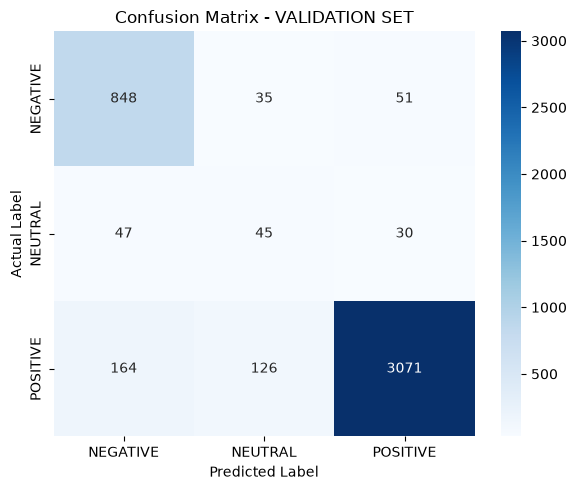


EVALUASI MODEL (SVM BASELINE) - TEST SET
Accuracy Score : 0.8940
Macro F1-Score : 0.7072

Detailed Classification Report:
              precision    recall  f1-score   support

    NEGATIVE       0.80      0.91      0.85       415
     NEUTRAL       0.26      0.46      0.33        54
    POSITIVE       0.97      0.90      0.94      1494

    accuracy                           0.89      1963
   macro avg       0.68      0.76      0.71      1963
weighted avg       0.91      0.89      0.90      1963



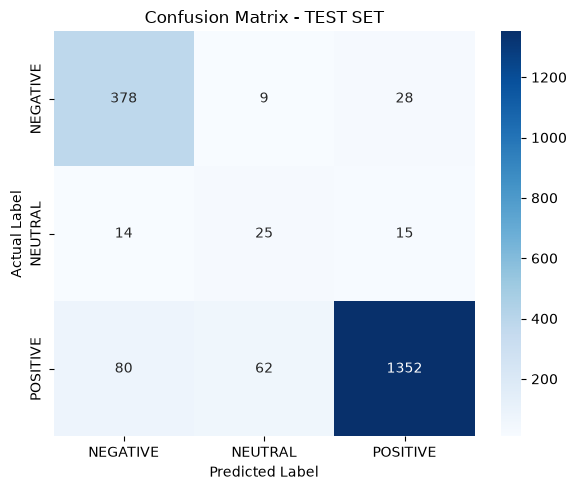

In [114]:
import sys, os
from pathlib import Path

ROOT_DIR = Path().cwd().parent
print(ROOT_DIR)
sys.path.insert(0, str(ROOT_DIR))
from config.config_script import SVM_DIR, TFIDF_DIR

pipeline = TFIDF_SVM_Baseline(
    df_train=train_df,
    df_val=val_df,
    df_test=test_df,
    target_col='sentiment',
    text_col='review_cleaned_normed',
    max_features=10000,
    weight_col='weight',
    sample_weight_map=None,
    debug=False,
)._fit_pipeline(
    model_path = SVM_DIR, vec_path=TFIDF_DIR, keep_model = False
)



#### C.1.2 TFIDF + SVM with Weight

c:\Users\Alvin\Music\Text Mining\TM & RM Project
--> Preprocessing teks untuk Train, Validation, dan Test set...
Data Siap! Train: 13248 | Val: 4417 | Test: 1963
--> Mengubah Teks menjadi Matriks TF-IDF...
Ukuran Matriks Fitur TF-IDF Train : (13248, 10000)
Ukuran Matriks Fitur TF-IDF Val   : (4417, 10000)
Ukuran Matriks Fitur TF-IDF Test  : (1963, 10000)
Sample Weight: [1. 1. 1. ... 1. 1. 1.]
Pelatihan Model SVM Selesai.

EVALUASI MODEL (SVM BASELINE) - VALIDATION SET
Accuracy Score : 0.8990
Macro F1-Score : 0.6909

Detailed Classification Report:
              precision    recall  f1-score   support

    NEGATIVE       0.81      0.90      0.85       934
     NEUTRAL       0.22      0.37      0.28       122
    POSITIVE       0.97      0.92      0.94      3361

    accuracy                           0.90      4417
   macro avg       0.67      0.73      0.69      4417
weighted avg       0.92      0.90      0.91      4417



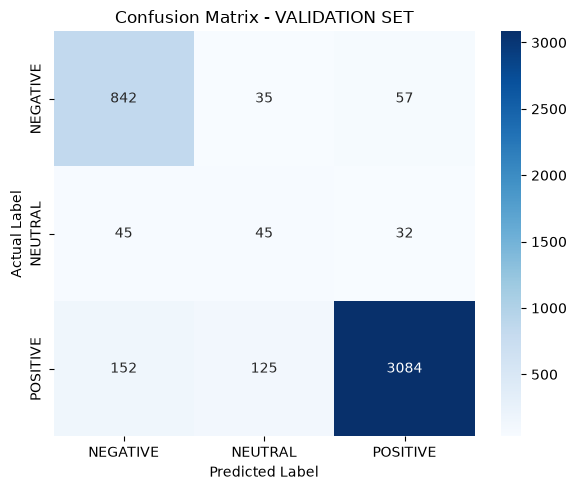


EVALUASI MODEL (SVM BASELINE) - TEST SET
Accuracy Score : 0.8976
Macro F1-Score : 0.7132

Detailed Classification Report:
              precision    recall  f1-score   support

    NEGATIVE       0.81      0.90      0.85       415
     NEUTRAL       0.28      0.46      0.35        54
    POSITIVE       0.97      0.91      0.94      1494

    accuracy                           0.90      1963
   macro avg       0.69      0.76      0.71      1963
weighted avg       0.91      0.90      0.90      1963



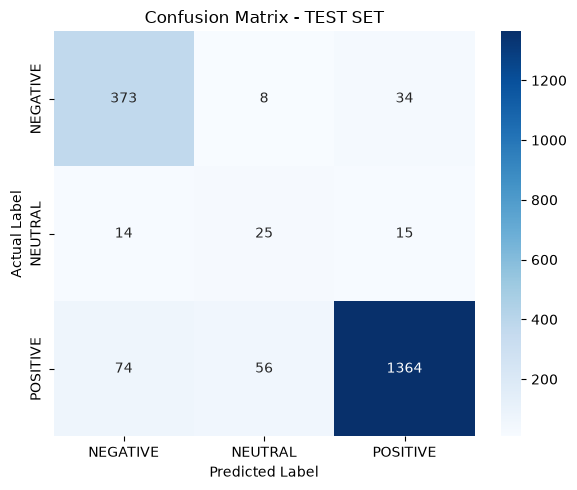

In [115]:
import sys, os
from pathlib import Path

ROOT_DIR = Path().cwd().parent
print(ROOT_DIR)
sys.path.insert(0, str(ROOT_DIR))
from config.config_script import SVM_DIR, TFIDF_DIR

pipeline = TFIDF_SVM_Baseline(
    df_train=train_df,
    df_val=val_df,
    df_test=test_df,
    target_col='sentiment',
    text_col='review_cleaned_normed',
    max_features=10000,
    weight_col='weight',
    sample_weight_map={
        'COMPLEX': 3.0,
        'INFORMATIVE': 2.0,
        'UNINFORMATIVE': 1.0,
    }
)._fit_pipeline(
    model_path = SVM_DIR, vec_path=TFIDF_DIR
)



In [112]:
stop()

NameError: name 'stop' is not defined

### C.2 indoBERT

In [ ]:
from transformers import AutoTokenizer
model_tokenizer = "indobenchmark/indobert-base-p1"

tokenizer = AutoTokenizer.from_pretrained(model_tokenizer)
sample_text = df["review_cleaned_normed"].iloc[9]

inputs = tokenizer(
    sample_text,
    padding="max_length",  # Menyamakkan panjang urutan
    truncation=True,  # Memotong teks jika melebihi max_length
    max_length=128,  # Panjang maksimum token (biasanya 128 atau 256)
    return_tensors="pt",  # Mengembalikan format PyTorch Tensor
)

print(inputs["input_ids"])  # ID Angka untuk setiap token
print(inputs["attention_mask"])  # Masking untuk padding (1 untuk kata asli, 0 untuk padding)

tensor([[    2,  1339,    92,   119, 10651,   209,  4755,    34,  8189,   469,
            26,  2785, 10900,   406,  3526,  3109,   599,   119,   166,  2785,
           406,    92,   119,  3370,   176,  3511,  8189,     3,     0,     0,
             0,     0,     0,     0,     0,     0,     0,     0,     0,     0,
             0,     0,     0,     0,     0,     0,     0,     0,     0,     0,
             0,     0,     0,     0,     0,     0,     0,     0,     0,     0,
             0,     0,     0,     0,     0,     0,     0,     0,     0,     0,
             0,     0,     0,     0,     0,     0,     0,     0,     0,     0,
             0,     0,     0,     0,     0,     0,     0,     0,     0,     0,
             0,     0,     0,     0,     0,     0,     0,     0,     0,     0,
             0,     0,     0,     0,     0,     0,     0,     0,     0,     0,
             0,     0,     0,     0,     0,     0,     0,     0,     0,     0,
             0,     0,     0,     0,     0,     0,  

In [ ]:
import torch
import torch.nn as nn
from sklearn.metrics import accuracy_score, classification_report, f1_score
from sklearn.model_selection import StratifiedGroupKFold
from torch.utils.data import DataLoader, Dataset
from transformers import AutoModelForSequenceClassification, AutoTokenizer, DataCollatorWithPadding

tokenizer = AutoTokenizer.from_pretrained(model_tokenizer)
raw_texts = df_final["review_cleaned_normed"].astype(str).tolist()

class IndoBERTDataset(Dataset):
    def __init__(self, texts, labels, tokenizer, max_len=128):
        self.texts  = texts
        self.labels = labels
        self.tokenizer = tokenizer
        self.max_len = max_len

    def __len__(self):
        return len(self.texts)
    
    def __getitem__(self, item):
        text = str(self.texts[item])
        label = self.labels[item]

        encoding = self.tokenizer(
            text,
            truncation=True,
            padding="max_length",
            max_length=self.max_len,
            return_tensors="pt",
        )

        return {
            "input_ids": encoding["input_ids"].flatten(),
            "attention_mask": encoding["attention_mask"].flatten(),
            "labels": torch.tensor(label, dtype=torch.long),
        }

train_df = df_final[df_final["split"] == "train"].reset_index(drop=True)
val_df = df_final[df_final["split"] == "val"].reset_index(drop=True)

train_dataset = IndoBERTDataset(
    train_df["review_cleaned_normed"].values,
    train_df["sentiment"].values,
    tokenizer,
)

val_dataset = IndoBERTDataset(
    val_df["review_cleaned_normed"].values, train_df["sentiment"].values, tokenizer
)

test_dataset = IndoBERTDataset(
    test_df["review_cleaned_normed"].values, train_df["sentiment"].values, tokenizer
)

train_loader = DataLoader(train_dataset, batch_size = 32, shuffle = True)
val_loader = DataLoader(val_dataset, batch_size=32)
test_loader = DataLoader(test_dataset, batch_size=32)

In [ ]:
real_text = tokenizer.decode(inputs["input_ids"][0])
print(real_text)

[CLS] aplikasi ini tidak amanah saya order yang instan tapi di kirim esok hari aneh seharusnya kalau tidak bisa kirim hari ini tidak usah ada pengiriman instan [SEP] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD]


In [ ]:
tokens = tokenizer.convert_ids_to_tokens(inputs['input_ids'][0])
tokens

['[CLS]',
 'aplikasi',
 'ini',
 'tidak',
 'amanah',
 'saya',
 'order',
 'yang',
 'instan',
 'tapi',
 'di',
 'kirim',
 'esok',
 'hari',
 'aneh',
 'seharusnya',
 'kalau',
 'tidak',
 'bisa',
 'kirim',
 'hari',
 'ini',
 'tidak',
 'usah',
 'ada',
 'pengiriman',
 'instan',
 '[SEP]',
 '[PAD]',
 '[PAD]',
 '[PAD]',
 '[PAD]',
 '[PAD]',
 '[PAD]',
 '[PAD]',
 '[PAD]',
 '[PAD]',
 '[PAD]',
 '[PAD]',
 '[PAD]',
 '[PAD]',
 '[PAD]',
 '[PAD]',
 '[PAD]',
 '[PAD]',
 '[PAD]',
 '[PAD]',
 '[PAD]',
 '[PAD]',
 '[PAD]',
 '[PAD]',
 '[PAD]',
 '[PAD]',
 '[PAD]',
 '[PAD]',
 '[PAD]',
 '[PAD]',
 '[PAD]',
 '[PAD]',
 '[PAD]',
 '[PAD]',
 '[PAD]',
 '[PAD]',
 '[PAD]',
 '[PAD]',
 '[PAD]',
 '[PAD]',
 '[PAD]',
 '[PAD]',
 '[PAD]',
 '[PAD]',
 '[PAD]',
 '[PAD]',
 '[PAD]',
 '[PAD]',
 '[PAD]',
 '[PAD]',
 '[PAD]',
 '[PAD]',
 '[PAD]',
 '[PAD]',
 '[PAD]',
 '[PAD]',
 '[PAD]',
 '[PAD]',
 '[PAD]',
 '[PAD]',
 '[PAD]',
 '[PAD]',
 '[PAD]',
 '[PAD]',
 '[PAD]',
 '[PAD]',
 '[PAD]',
 '[PAD]',
 '[PAD]',
 '[PAD]',
 '[PAD]',
 '[PAD]',
 '[PAD]',
 '

In [ ]:
unk_id = tokenizer.unk_token_id 
unk_count = (inputs["input_ids"] == unk_id).sum().item()
print(f"Jumlah token [UNK]: {unk_count}")

Jumlah token [UNK]: 0


INPUT_IDS DESCRIPTION:

- angka: 2 CLS -> Token khusus awal kalimat yang di auto-assign oleh indoBERT.

- Angka 1339, 92, 119, ...: Token ID untuk kata-kata dalam ulasanmu (misalnya "aplikasi", "bagus", "suka", dll).

- Deretan angka 0 di belakang: Token khusus [PAD] (padding). Karena kamu menetapkan max_length=128, sisa ruang kosong diisi angka 0 agar ukurannya pas 128 elemen.

- angka: 3 CLS -> Token khusus akhir kalimat yang di auto-assign oleh indoBERT.

ATTENTION MASK:
- 1 -> token asli
0 -> Token padding, diabaikan saat proses attention mechanism

In [ ]:
token_lengths = [
    len(tokenizer.encode(text, truncation=False))
    for text in df["review_cleaned_normed"]
]

print(pd.Series(token_lengths).describe(percentiles=[0.5, 0.9, 0.95, 0.99]))

count    19680.000000
mean        15.215752
std         14.272902
min          2.000000
50%         10.000000
90%         32.000000
95%         44.000000
99%         76.000000
max        125.000000
dtype: float64


set max_length = 125

In [ ]:
class indoBERT():
    def __init__(self, debug = True):
        self.label = df["sentiment"].unique()
        self.num_labels = len(df["sentiment"].unique())

        self.id2label = {0: "negative", 1: "neutral", 2: "positive"}
        self.label2id = {"negative": 0, "neutral": 1, "positive": 2}

        if debug == True:
            print(
                  f"id2label:\t{self.id2label}", "\n"
                  f"label2id:\t{self.label2id}"
            )

        from transformers import AutoModelForSequenceClassification
        from transformers import Trainer, TrainingArguments

        self.model = AutoModelForSequenceClassification.from_pretrained(
            model_tokenizer,
            num_labels=len(id2label),
            id2label=id2label,
            label2id=label2id,
            ignore_mismatched_sizes=True,  # Mengabaikan perbedaan ukuran matriks bobot terakhir dari checkpoint lama
        )

        self.training_args = TrainingArguments(
            output_dir="./results",
            num_train_epochs=3,  # Biasanya 3-5 epoch cukup untuk fine-tuning BERT
            per_device_train_batch_size=32,
            per_device_eval_batch_size=32,
            learning_rate=2e-5,  # Learning rate kecil khusus Transformers (1e-5 s/d 5e-5)
            # evaluation_strategy="epoch",  # Evaluasi setiap selesai 1 epoch
            save_strategy="best",
            load_best_model_at_end=True,  # Simpan model dengan performa validation terbaik
            metric_for_best_model="f1_macro",  # Pakai F1-score sebagai acuan utama
            seed=42,
        )
        
        